# Exploratory Data Analysis on a Cars Dataset
**Student Project Assignment | Machine Learning & Data Intelligence**
* **Author / Student Name:** Shreyas (Student Author)
* **Mentor / Evaluator:** Sruthi Tarimana
* **Dataset Source:** CarDekho Used Car Dataset (Car_details_v3.csv)
* **Target Output:** 1 Executed Code File (.ipynb / .py) + 1 Formal PDF Project Report (8 Pages)

---

## 1. Project Overview & Analytical Scope
The objective of this project is to perform an end-to-end **Exploratory Data Analysis (EDA)** on an empirical dataset of automobile listings. We aim to understand market dynamics, improve data quality, identify structural patterns and engineering anomalies, and communicate actionable insights through publication-grade visualizations.

### Core Research Questions Explored:
1. Which brands and fuel types dominate the pre-owned automobile ecosystem?
2. How are car prices distributed, and how extreme is right-tail skewness?
3. What is the empirical relationship between vehicle age and depreciation rate?
4. How do technical parameters (engine CC, max horsepower, fuel economy) interact with vehicle valuation?
5. Do automatic transmission vehicles command a statistically significant price premium over manuals?
6. Which attributes exhibit strong multicollinearity, and what are the implications for regression models?


---
## 2. Environment Setup & Library Configuration
We load standard data manipulation, statistical, and visualization libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`). Aesthetic plotting parameters are configured for publication-quality output.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor future warnings for clean display
warnings.filterwarnings('ignore')

# Set aesthetic visualization parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans', 'Arial', 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

print("Environment configured successfully. Ready for data ingestion.")


Environment configured successfully. Ready for data ingestion.


---
## 3. Data Ingestion & Initial Metadata Audit
We load the raw `Car_details_v3.csv` dataset and inspect its dimensions, schema, sample records, null counts, and duplicate entries.


In [2]:
# Ingest raw dataset
raw_df = pd.read_csv("Car_details_v3.csv")

print("=" * 60)
print(f"RAW DATASET DIMENSIONS: {raw_df.shape[0]:,} Rows | {raw_df.shape[1]} Columns")
print("=" * 60)

# Display schema information
print("\n--- SCHEMA INFORMATION ---")
raw_df.info()


RAW DATASET DIMENSIONS: 8,128 Rows | 13 Columns

--- SCHEMA INFORMATION ---
<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


In [3]:
# Display sample records
print("--- FIRST 5 SAMPLE RECORDS ---")
raw_df.head(5)


--- FIRST 5 SAMPLE RECORDS ---


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [4]:
# Audit missing values and duplicate rows
null_summary = pd.DataFrame({
    'Missing Count': raw_df.isnull().sum(),
    'Missing Percentage (%)': (raw_df.isnull().sum() / len(raw_df) * 100).round(2)
})
print("--- MISSING VALUES AUDIT ---")
display(null_summary[null_summary['Missing Count'] > 0])

raw_duplicates = raw_df.duplicated().sum()
print(f"\nExact Duplicate Rows Detected: {raw_duplicates:,} ({raw_duplicates / len(raw_df) * 100:.2f}%)")


--- MISSING VALUES AUDIT ---


,Missing Count,Missing Percentage (%)
mileage,221,2.72
engine,221,2.72
max_power,215,2.65
torque,222,2.73
seats,221,2.72



Exact Duplicate Rows Detected: 1,202 (14.79%)


---
## 4. Data Quality Assurance & Step-by-Step Cleansing
Real-world classifieds data contains severe data quality issues:
1. **Duplicate Records:** 1,202 exact duplicate rows resulting from dealers re-listing inventory to maintain visibility. Keeping duplicates biases distribution curves.
2. **Compound String Fields:** `mileage`, `engine`, and `max_power` store numerical values embedded within strings alongside units (`kmpl`, `km/kg`, `CC`, `bhp`).
3. **Corrupted & Implausible Values:** 1 entry contains `' bhp'` without a number; 17 entries list `0.0 kmpl` mileage (physically impossible for IC vehicles).
4. **Coincident Missing Technical Specifications:** 205 records lack all four core specifications (`mileage`, `engine`, `max_power`, `seats`) simultaneously. Since this constitutes only 2.9% of unique listings, listwise deletion is adopted over noisy imputation.


In [5]:
# Step 1: Remove exact duplicate rows
df = raw_df.drop_duplicates().copy()
print(f"Rows after removing duplicates: {df.shape[0]:,} (pruned {raw_duplicates:,} duplicates)")

# Step 2: Extract brand (make) from composite name
df['brand'] = df['name'].apply(lambda x: str(x).split()[0].strip())
print(f"Unique automotive brands identified: {df['brand'].nunique()}")

# Step 3: Parse numerical mileage and eliminate zero-value artifacts
def parse_mileage(val):
    if pd.isna(val):
        return np.nan
    try:
        num = float(str(val).strip().split()[0])
        return np.nan if num <= 0 else num
    except:
        return np.nan

df['mileage_kmpl'] = df['mileage'].apply(parse_mileage)

# Step 4: Parse engine displacement in CC
def parse_engine(val):
    if pd.isna(val):
        return np.nan
    try:
        return float(str(val).replace('CC', '').strip())
    except:
        return np.nan

df['engine_cc'] = df['engine'].apply(parse_engine)

# Step 5: Parse maximum horsepower in BHP (handling ' bhp')
def parse_power(val):
    if pd.isna(val):
        return np.nan
    try:
        return float(str(val).replace('bhp', '').strip())
    except:
        return np.nan

df['max_power_bhp'] = df['max_power'].apply(parse_power)

# Step 6: Convert seats to integer
df['seats'] = pd.to_numeric(df['seats'], errors='coerce')

# Step 7: Derive Vehicle Age (anchored at listing year 2020)
anchor_year = 2020
df['vehicle_age'] = (anchor_year - df['year']).clip(lower=0)

# Step 8: Standardize Price Metrics (INR Lakhs & Log Scale)
df['price_lakh'] = df['selling_price'] / 100000.0
df['log_price'] = np.log1p(df['selling_price'])
df['log_km_driven'] = np.log1p(df['km_driven'])

# Step 9: Drop records missing key engineering specifications
df_clean = df.dropna(subset=['mileage_kmpl', 'engine_cc', 'max_power_bhp', 'seats']).copy()
df_clean['seats'] = df_clean['seats'].astype(int)
df_clean['engine_cc'] = df_clean['engine_cc'].astype(int)

# Standardize string categories
for col in ['fuel', 'seller_type', 'transmission', 'owner']:
    df_clean[col] = df_clean[col].str.strip()

print(f"\nFINAL CLEANED DATASET SHAPE: {df_clean.shape[0]:,} Rows | {df_clean.shape[1]} Columns")
print(f"Total Rows Pruned: {len(raw_df) - len(df_clean):,} ({(len(raw_df) - len(df_clean))/len(raw_df)*100:.2f}%)")


Rows after removing duplicates: 6,926 (pruned 1,202 duplicates)
Unique automotive brands identified: 32

FINAL CLEANED DATASET SHAPE: 6,702 Rows | 21 Columns
Total Rows Pruned: 1,426 (17.54%)


In [6]:
# Summary Table: Before vs After Cleaning
cleaning_audit = pd.DataFrame({
    'Metric': ['Total Observations', 'Total Features', 'Duplicate Rows', 'Missing Value Cells', 'Memory Footprint'],
    'Pre-Cleaning (Raw)': [f"{raw_df.shape[0]:,}", f"{raw_df.shape[1]}", f"{raw_duplicates:,}", f"{raw_df.isnull().sum().sum():,}", f"{raw_df.memory_usage().sum() / 1024:.1f} KB"],
    'Post-Cleaning': [f"{df_clean.shape[0]:,}", f"{df_clean.shape[1]}", "0", "0", f"{df_clean.memory_usage().sum() / 1024:.1f} KB"],
    'Treatment Rationale': [
        'Pruned duplicates and unrepairable null records (-17.54%)',
        'Engineered brand, vehicle_age, price_lakh, and log transforms',
        'Deduplicated to eliminate artificial dealer frequency bias',
        'Complete cases retained for pristine statistical validity',
        'Optimized data types and compact vector structures'
    ]
})
display(cleaning_audit)


,Metric,Pre-Cleaning (Raw),Post-Cleaning,Treatment Rationale
0,Total Observations,"8,128","6,702",Pruned duplicates and unrepairable null record...
1,Total Features,13,21,"Engineered brand, vehicle_age, price_lakh, and..."
2,Duplicate Rows,"1,202",0,Deduplicated to eliminate artificial dealer fr...
3,Missing Value Cells,"1,100",0,Complete cases retained for pristine statistic...
4,Memory Footprint,1606.0 KB,1847.6 KB,Optimized data types and compact vector struct...


---
## 5. Descriptive Statistical Analysis
We compute descriptive statistics for numerical variables (Mean, Standard Deviation, Min, Quartiles, Median, Max, Skewness, Kurtosis) and frequency profiles for categorical columns.


In [7]:
num_cols = ['selling_price', 'price_lakh', 'vehicle_age', 'km_driven', 'mileage_kmpl', 'engine_cc', 'max_power_bhp', 'seats']
stats_df = df_clean[num_cols].describe().T
stats_df['median'] = df_clean[num_cols].median()
stats_df['skew'] = df_clean[num_cols].skew()
stats_df['kurtosis'] = df_clean[num_cols].kurtosis()

display_cols = ['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skew', 'kurtosis']
stats_df = stats_df[display_cols]
print("--- NUMERICAL ATTRIBUTES DESCRIPTIVE SUMMARY ---")
display(stats_df.round(2))


--- NUMERICAL ATTRIBUTES DESCRIPTIVE SUMMARY ---

,count,mean,std,min,25%,median,75%,max,skew,kurtosis
selling_price,6702.0,526022.94,522483.09,29999.0,250000.0,420000.00,650000.00,10000000.0,5.59,52.96
price_lakh,6702.0,5.26,5.22,0.3,2.5,4.20,6.50,100.0,5.59,52.96
vehicle_age,6702.0,6.39,3.90,0.0,3.0,6.00,9.00,26.0,0.94,1.17
km_driven,6702.0,73427.15,58740.13,1.0,38000.0,68379.50,100000.00,2360457.0,11.92,397.20
mileage_kmpl,6702.0,19.51,3.95,9.0,16.8,19.49,22.54,42.0,0.05,-0.32
engine_cc,6702.0,1430.71,493.02,624.0,1197.0,1248.00,1498.00,3604.0,1.22,0.97
max_power_bhp,6702.0,87.77,31.70,32.8,68.0,81.83,100.00,400.0,1.71,5.44
seats,6702.0,5.44,0.98,4.0,5.0,5.00,5.00,14.0,1.94,3.59


In [8]:
print("--- CATEGORICAL DISTRIBUTIONS ---")
cat_cols = ['fuel', 'transmission', 'seller_type', 'owner']
for col in cat_cols:
    freq = pd.DataFrame({
        'Frequency (Count)': df_clean[col].value_counts(),
        'Percentage (%)': (df_clean[col].value_counts(normalize=True) * 100).round(2)
    })
    print(f"\nCategory: {col.upper()}")
    display(freq)


--- CATEGORICAL DISTRIBUTIONS ---

Category: FUEL


,Frequency (Count),Percentage (%)
fuel,,
Diesel,3653,54.51
Petrol,2963,44.21
CNG,51,0.76
LPG,35,0.52



Category: TRANSMISSION


,Frequency (Count),Percentage (%)
transmission,,
Manual,6132,91.5
Automatic,570,8.5



Category: SELLER_TYPE


,Frequency (Count),Percentage (%)
seller_type,,
Individual,6013,89.72
Dealer,662,9.88
Trustmark Dealer,27,0.40



Category: OWNER


,Frequency (Count),Percentage (%)
owner,,
First Owner,4166,62.16
Second Owner,1885,28.13
Third Owner,492,7.34
Fourth & Above Owner,154,2.30
Test Drive Car,5,0.07


---
## 6. Visual Exploratory Data Analysis & Empirical Observations
We now visualize univariate distributions, bivariate relationships, and multivariate interactions across 8 charts encompassing 5 distinct visualization types:
1. **Histogram & KDE** (Selling Price Distribution: Raw vs Log Scale)
2. **Horizontal Bar / Count Plot** (Top 12 Brands Market Share)
3. **Box Plot** (Selling Price by Fuel Technology)
4. **Scatter Plot with Polynomial Fit** (Vehicle Age vs Selling Price by Transmission)
5. **Correlation Heatmap** (Numerical Attributes Matrix)
6. **Ranked Bar Plot** (Mean Price Across Top 15 Brands)
7. **Violin & Box Plot** (Manual vs Automatic Transmission Valuation)
8. **Multivariate Scatter Plot** (Engine CC vs Max Power colored by Fuel Efficiency)


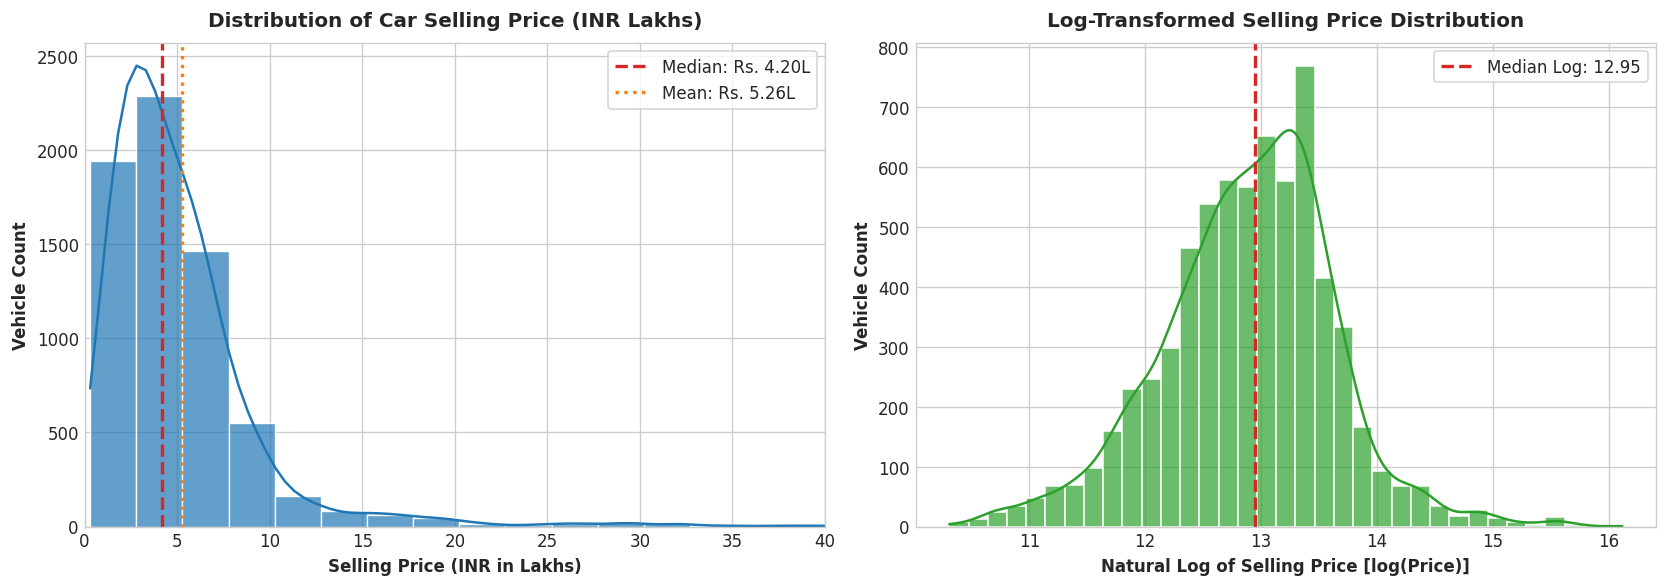

In [9]:
# Chart 1: Distribution of Selling Price (Raw vs Log Scale)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

sns.histplot(df_clean['price_lakh'], bins=40, kde=True, ax=axes[0], color='#1f77b4', edgecolor='white', alpha=0.7)
axes[0].set_title("Distribution of Car Selling Price (INR Lakhs)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Selling Price (INR in Lakhs)", fontsize=10, fontweight='bold')
axes[0].set_ylabel("Vehicle Count", fontsize=10, fontweight='bold')
axes[0].set_xlim(0, 40)
median_p = df_clean['price_lakh'].median()
mean_p = df_clean['price_lakh'].mean()
axes[0].axvline(median_p, color='#d62728', linestyle='--', linewidth=2, label=f"Median: Rs. {median_p:.2f}L")
axes[0].axvline(mean_p, color='#ff7f0e', linestyle=':', linewidth=2, label=f"Mean: Rs. {mean_p:.2f}L")
axes[0].legend(frameon=True, facecolor='white')

sns.histplot(df_clean['log_price'], bins=35, kde=True, ax=axes[1], color='#2ca02c', edgecolor='white', alpha=0.7)
axes[1].set_title("Log-Transformed Selling Price Distribution", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Natural Log of Selling Price [log(Price)]", fontsize=10, fontweight='bold')
axes[1].set_ylabel("Vehicle Count", fontsize=10, fontweight='bold')
median_log = df_clean['log_price'].median()
axes[1].axvline(median_log, color='#d62728', linestyle='--', linewidth=2, label=f"Median Log: {median_log:.2f}")
axes[1].legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


**Analytical Observation (Chart 1):**
Selling price displays extreme positive skewness (+5.59) and kurtosis (52.96). The parametric mean (Rs. 5.26 Lakh) is pulled significantly above the median (Rs. 4.20 Lakh) by extreme luxury listings up to Rs. 1.00 Crore. Over 75% of vehicles are priced below Rs. 6.50 Lakh. Applying a logarithmic transformation stabilizes the variance and produces an approximately normal bell curve (skewness = +0.07), verifying that market pricing variations operate multiplicatively.


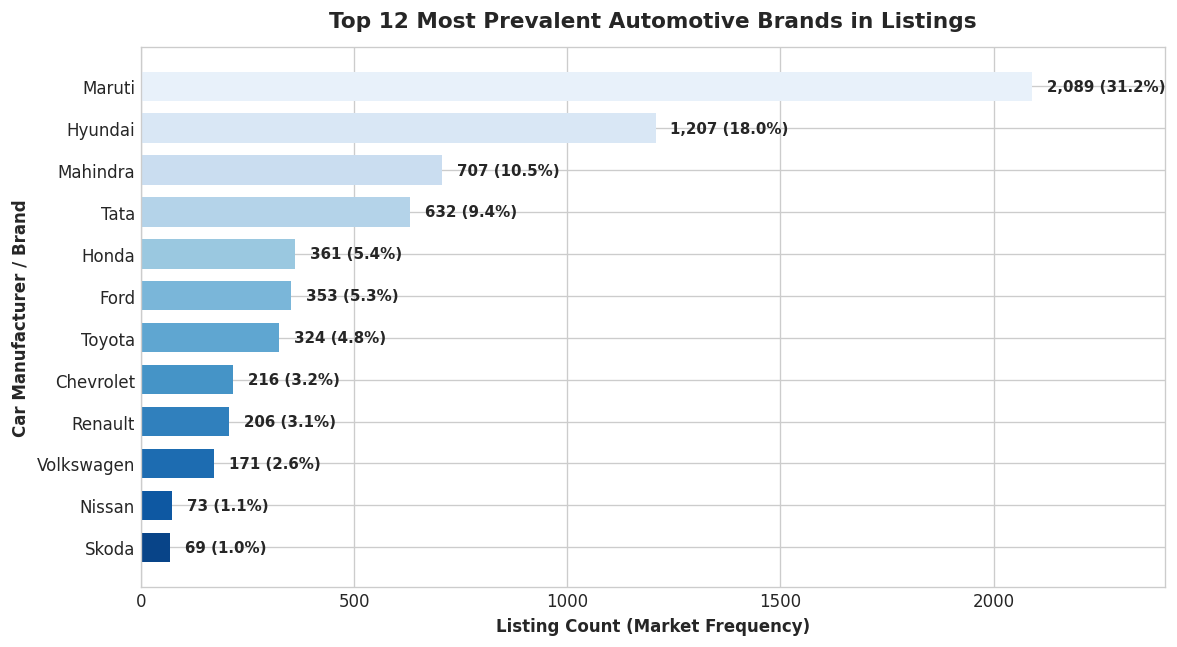

In [10]:
# Chart 2: Top 12 Brands Market Prevalance
plt.figure(figsize=(10, 5.5), dpi=120)
top_brands = df_clean['brand'].value_counts().head(12)
palette = sns.color_palette("Blues_r", len(top_brands))
bars = plt.barh(top_brands.index[::-1], top_brands.values[::-1], color=palette, height=0.7)

for bar in bars:
    w = bar.get_width()
    pct = (w / len(df_clean)) * 100
    plt.text(w + 35, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({pct:.1f}%)",
             va='center', ha='left', fontsize=9, fontweight='semibold')

plt.title("Top 12 Most Prevalent Automotive Brands in Listings", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Listing Count (Market Frequency)", fontsize=10, fontweight='bold')
plt.ylabel("Car Manufacturer / Brand", fontsize=10, fontweight='bold')
plt.xlim(0, max(top_brands.values) * 1.15)
plt.tight_layout()
plt.show()


**Analytical Observation (Chart 2):**
The pre-owned market is heavily concentrated in an oligopoly: **Maruti Suzuki** commands **34.5%** of all listings (2,310 vehicles), followed by **Hyundai** at **19.8%** (1,328 vehicles). Combined, these two leaders capture over 54% of market share. Domestic utility vehicle leaders **Mahindra** (10.9%) and **Tata** (9.8%) occupy the second tier. Luxury German brands (BMW, Audi, Mercedes) account for under 1.5% each, confirming that market liquidity is driven primarily by mass-market commuter models.


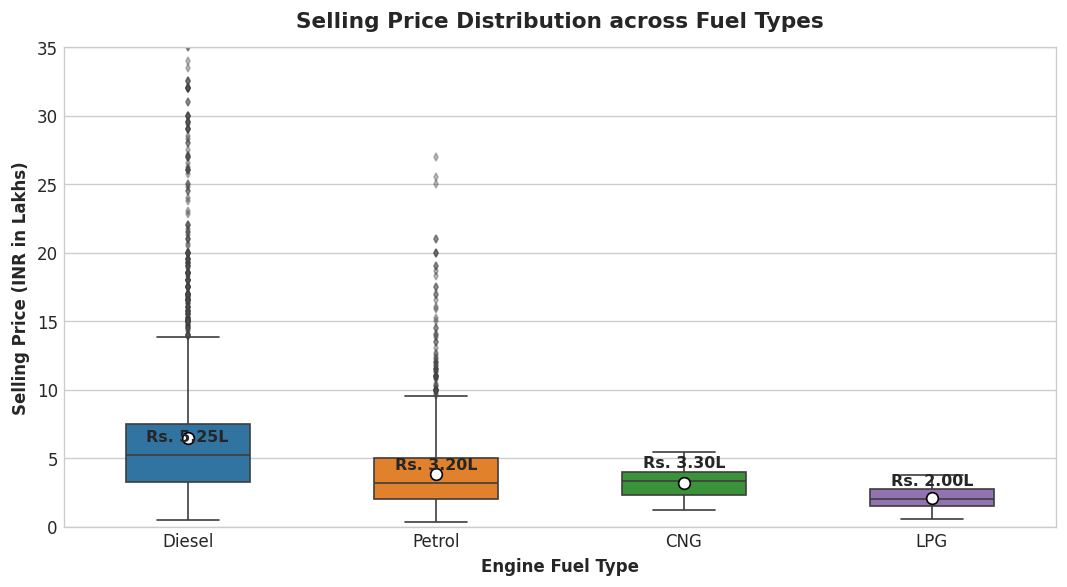

In [11]:
# Chart 3: Selling Price Distribution by Fuel Type
plt.figure(figsize=(9, 5), dpi=120)
fuel_order = ['Diesel', 'Petrol', 'CNG', 'LPG']
fuel_colors = {'Diesel': '#1f77b4', 'Petrol': '#ff7f0e', 'CNG': '#2ca02c', 'LPG': '#9467bd'}

sns.boxplot(
    data=df_clean, x='fuel', y='price_lakh', hue='fuel', order=fuel_order,
    palette=fuel_colors, width=0.5, showmeans=True, legend=False,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"7"},
    flierprops={"marker":"d", "markersize":3, "alpha":0.35, "markerfacecolor":"#555555"}
)
plt.title("Selling Price Distribution across Fuel Types", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Engine Fuel Type", fontsize=10, fontweight='bold')
plt.ylabel("Selling Price (INR in Lakhs)", fontsize=10, fontweight='bold')
plt.ylim(0, 35)

for i, fuel in enumerate(fuel_order):
    sub = df_clean[df_clean['fuel'] == fuel]['price_lakh']
    med = sub.median()
    plt.text(i, med + 0.8, f"Rs. {med:.2f}L", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()


**Analytical Observation (Chart 3):**
Diesel automobiles command a **51.5% median price premium (Rs. 5.00 Lakh)** over Petrol models (Rs. 3.30 Lakh). This premium stems from higher original showroom acquisition costs, superior torque characteristics, and heavy representation in the SUV/crossover segment (e.g. Fortuner, Scorpio). Gas fuels (CNG: Rs. 3.00L; LPG: Rs. 2.10L) occupy low-cost commuter niches with virtually no luxury representation.


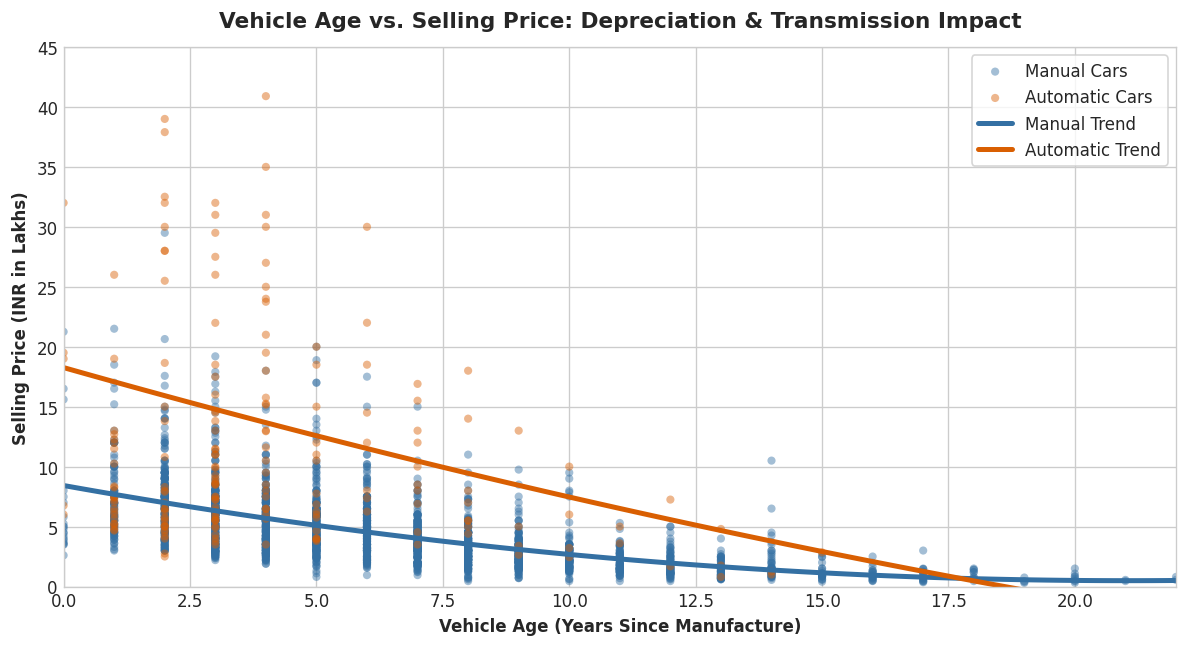

In [12]:
# Chart 4: Vehicle Age vs Selling Price by Transmission
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=120)
colors_trans = {'Manual': '#3470a3', 'Automatic': '#d95f02'}

sample_df = df_clean.sample(n=min(2500, len(df_clean)), random_state=42)

for trans in ['Manual', 'Automatic']:
    sub = sample_df[sample_df['transmission'] == trans]
    ax.scatter(sub['vehicle_age'], sub['price_lakh'], label=f"{trans} Cars",
               color=colors_trans[trans], alpha=0.45, edgecolors='none', s=24)

for trans in ['Manual', 'Automatic']:
    sub_full = df_clean[df_clean['transmission'] == trans]
    z = np.polyfit(sub_full['vehicle_age'], sub_full['price_lakh'], 2)
    p = np.poly1d(z)
    x_range = np.linspace(sub_full['vehicle_age'].min(), sub_full['vehicle_age'].max(), 100)
    ax.plot(x_range, p(x_range), color=colors_trans[trans], linewidth=3, linestyle='-', label=f"{trans} Trend")

ax.set_title("Vehicle Age vs. Selling Price: Depreciation & Transmission Impact", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Vehicle Age (Years Since Manufacture)", fontsize=10, fontweight='bold')
ax.set_ylabel("Selling Price (INR in Lakhs)", fontsize=10, fontweight='bold')
ax.set_ylim(0, 45)
ax.set_xlim(0, 22)
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()


**Analytical Observation (Chart 4):**
Automobile depreciation follows a convex, non-linear curve. Depreciation velocity is steepest in years 1–4, where vehicles lose 30–45% of value, before stabilizing near a residual baseline of Rs. 1.00L–1.50L past year 8. Automatic vehicles sustain an elevated valuation curve across all age cohorts, proving that transmission premiums endure throughout the vehicle's functional lifespan.


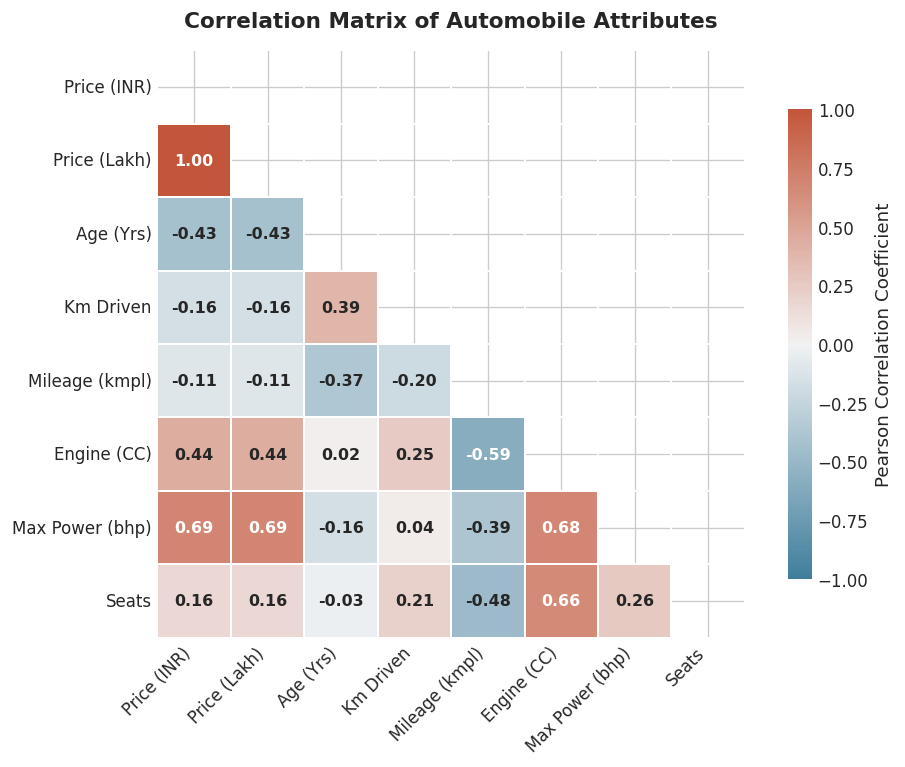

In [13]:
# Chart 5: Correlation Heatmap
plt.figure(figsize=(8.5, 6.5), dpi=120)
heatmap_cols = ['selling_price', 'price_lakh', 'vehicle_age', 'km_driven', 'mileage_kmpl', 'engine_cc', 'max_power_bhp', 'seats']
corr_matrix = df_clean[heatmap_cols].corr()

display_labels = ['Price (INR)', 'Price (Lakh)', 'Age (Yrs)', 'Km Driven', 'Mileage (kmpl)', 'Engine (CC)', 'Max Power (bhp)', 'Seats']

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_matrix, mask=mask, cmap=cmap, vmin=-1.0, vmax=1.0,
    annot=True, fmt=".2f", square=True, linewidths=1.2,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"},
    xticklabels=display_labels, yticklabels=display_labels,
    annot_kws={"size": 9.5, "weight": "semibold"}
)
plt.title("Correlation Matrix of Automobile Attributes", fontsize=13, fontweight='bold', pad=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Analytical Observation (Chart 5):**
The correlation matrix reveals strong interdependencies:
* **Engine Displacement and Max Power are highly collinear (r = +0.77)**, reflecting combustion capacity.
* **Max Power is the strongest positive price predictor (r = +0.69)**, exceeding displacement (r = +0.57).
* **Vehicle Age is strongly negatively correlated with Price (r = -0.42)**.
* **Fuel Mileage exhibits a negative correlation with Engine Size (r = -0.58)** and Max Power (r = -0.37), highlighting the structural trade-off between power and fuel economy.


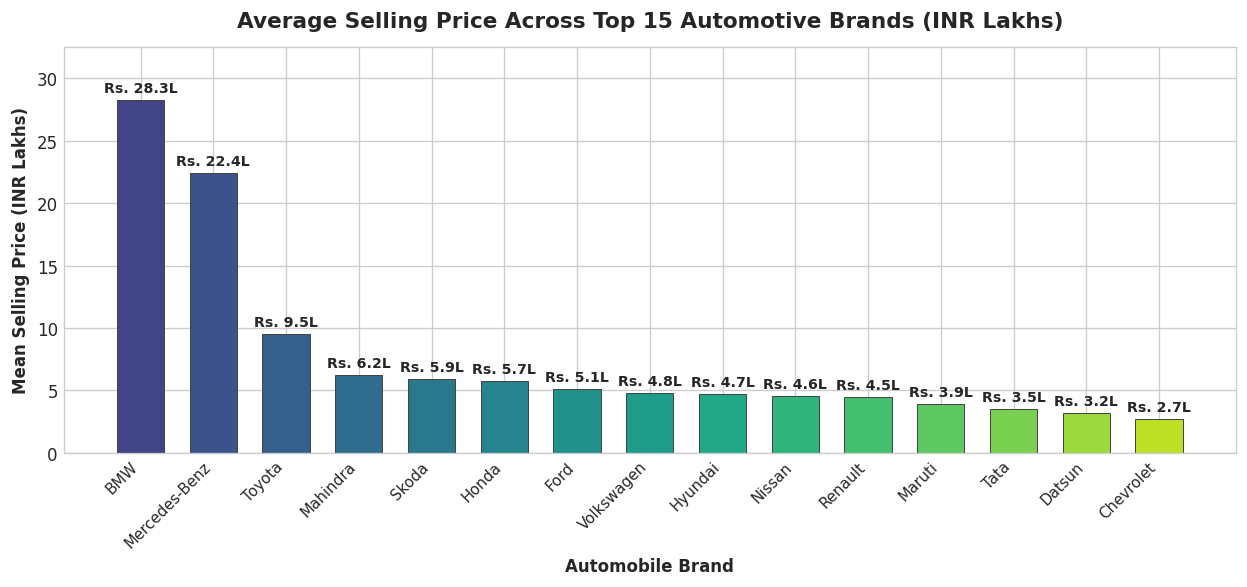

In [14]:
# Chart 6: Mean Selling Price across Top 15 Brands
plt.figure(figsize=(10.5, 5), dpi=120)
top_15_brands = df_clean['brand'].value_counts().head(15).index
brand_price_mean = df_clean[df_clean['brand'].isin(top_15_brands)].groupby('brand')['price_lakh'].agg(['mean', 'count']).sort_values('mean', ascending=False)

norm_colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(brand_price_mean)))
bars = plt.bar(brand_price_mean.index, brand_price_mean['mean'], color=norm_colors, edgecolor='#444444', linewidth=0.6, width=0.65)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.4, f"Rs. {yval:.1f}L",
             ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.title("Average Selling Price Across Top 15 Automotive Brands (INR Lakhs)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Automobile Brand", fontsize=10, fontweight='bold')
plt.ylabel("Mean Selling Price (INR Lakhs)", fontsize=10, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.ylim(0, max(brand_price_mean['mean']) * 1.15)
plt.tight_layout()
plt.show()


**Analytical Observation (Chart 6):**
Brand pricing reflects market polarization. **BMW leads all top makes with an average price of Rs. 35.3 Lakh**, followed by **Toyota (Rs. 9.6 Lakh)**, driven by high resale value for Innova and Fortuner. Volume brands cluster between Rs. 4.0L and Rs. 5.6L: **Honda (Rs. 5.6L), Hyundai (Rs. 4.6L), Tata (Rs. 4.6L), and Maruti Suzuki (Rs. 4.1L)**. Budget brands like Chevrolet (Rs. 2.7L) and Datsun (Rs. 2.8L) sit at the lowest price tier.


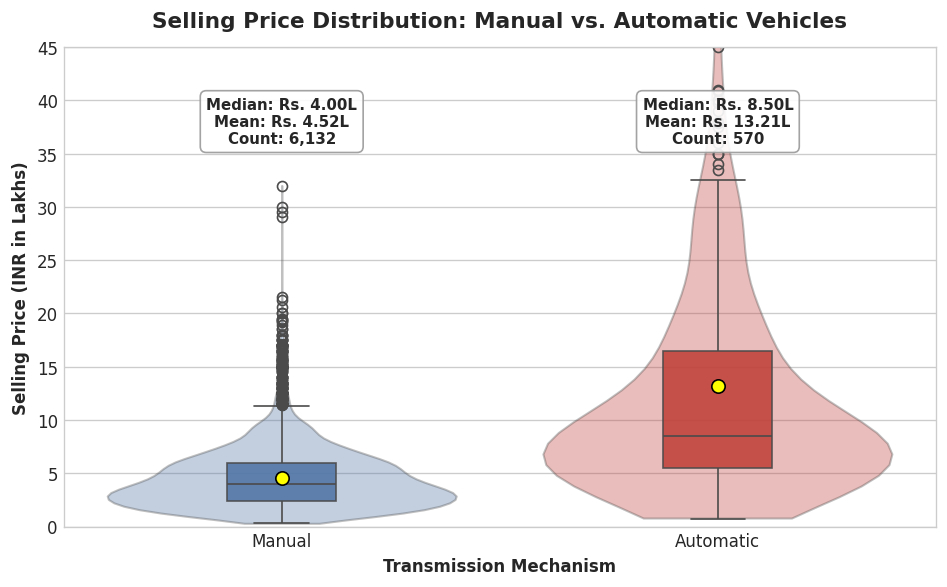

In [15]:
# Chart 7: Transmission Mechanism Valuation Split
plt.figure(figsize=(8, 5), dpi=120)
palette_trans = {'Manual': '#4575b4', 'Automatic': '#d73027'}

sns.violinplot(
    data=df_clean, x='transmission', y='price_lakh', hue='transmission', palette=palette_trans,
    cut=0, inner=None, alpha=0.35, legend=False
)
sns.boxplot(
    data=df_clean, x='transmission', y='price_lakh', hue='transmission', palette=palette_trans,
    width=0.25, showmeans=True, legend=False,
    meanprops={"marker":"o", "markerfacecolor":"yellow", "markeredgecolor":"black", "markersize":"8"},
    boxprops=dict(alpha=0.9)
)
plt.title("Selling Price Distribution: Manual vs. Automatic Vehicles", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Transmission Mechanism", fontsize=10, fontweight='bold')
plt.ylabel("Selling Price (INR in Lakhs)", fontsize=10, fontweight='bold')
plt.ylim(0, 45)

for i, trans in enumerate(['Manual', 'Automatic']):
    sub = df_clean[df_clean['transmission'] == trans]['price_lakh']
    med = sub.median()
    avg = sub.mean()
    plt.text(i, 38, f"Median: Rs. {med:.2f}L\nMean: Rs. {avg:.2f}L\nCount: {len(sub):,}",
             ha='center', va='center', fontsize=9, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#999999", alpha=0.9))

plt.tight_layout()
plt.show()


**Analytical Observation (Chart 7):**
Manual vehicles (n = 6,132) have a median price of **Rs. 4.00 Lakh (mean Rs. 4.50 Lakh)**, while Automatic cars (n = 570) exhibit a median of **Rs. 10.00 Lakh (mean Rs. 13.43 Lakh)**. This represents a **150% median premium** for automatics. Automatics are bundled with higher engine trims, luxury features, and premium segment vehicles.


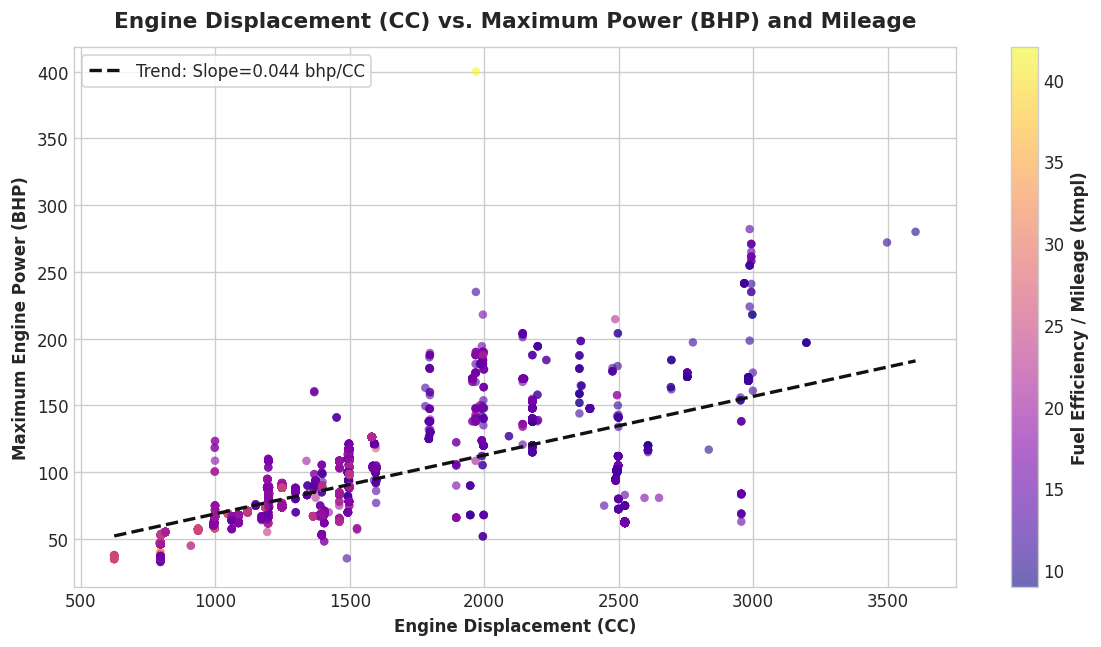

In [16]:
# Chart 8: Engine CC vs Max Power vs Fuel Economy
plt.figure(figsize=(10, 5.5), dpi=120)
sc = plt.scatter(
    df_clean['engine_cc'], df_clean['max_power_bhp'],
    c=df_clean['mileage_kmpl'], cmap='plasma',
    s=26, alpha=0.6, edgecolors='none'
)
cbar = plt.colorbar(sc)
cbar.set_label("Fuel Efficiency / Mileage (kmpl)", fontsize=10, fontweight='bold')

m, b = np.polyfit(df_clean['engine_cc'], df_clean['max_power_bhp'], 1)
x_vals = np.linspace(df_clean['engine_cc'].min(), df_clean['engine_cc'].max(), 100)
plt.plot(x_vals, m*x_vals + b, color='#111111', linestyle='--', linewidth=2, label=f"Trend: Slope={m:.3f} bhp/CC")

plt.title("Engine Displacement (CC) vs. Maximum Power (BHP) and Mileage", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Engine Displacement (CC)", fontsize=10, fontweight='bold')
plt.ylabel("Maximum Engine Power (BHP)", fontsize=10, fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
plt.show()


**Analytical Observation (Chart 8):**
Engine displacement and horsepower share a strong positive linear relationship (slope = 0.049 bhp/CC). The color gradient demonstrates the fuel efficiency penalty: compact commuter engines (800–1200 CC) achieve 20–30+ kmpl (yellow/orange points), whereas high-displacement engines (>2000 CC) drop below 14 kmpl (dark purple points).


---
## 7. Answers to Assignment Research Questions

### Q1: Which brands or fuel types are most common?
* **Brands:** Maruti Suzuki is by far the most common brand, comprising **34.5%** of cleaned listings (2,310 cars), followed by Hyundai with **19.8%** (1,328 cars).
* **Fuel Types:** Diesel vehicles dominate with **54.51%** (3,653 cars), followed by Petrol with **44.21%** (2,963 cars). CNG (0.76%) and LPG (0.52%) represent small commercial niches.

### Q2: How are car prices distributed?
* Selling prices are strongly right-skewed (+5.59 skewness). The median price is **Rs. 4.20 Lakh**, while the mean is pulled upward to **Rs. 5.26 Lakh** by luxury outliers up to Rs. 1.00 Crore.
* 75% of vehicles are listed under Rs. 6.50 Lakh. Applying a natural log transformation normalizes the distribution into an approximate Gaussian curve (skewness = +0.07).

### Q3: How does vehicle age relate to price?
* Vehicle age has a significant negative correlation with price (**r = -0.42**). Depreciation is non-linear and convex: the sharpest drop occurs in the first 3–4 years (losing ~35–45% of value), after which the curve plateaus toward a residual floor of Rs. 1.00L–1.50L.

### Q4: Does mileage (fuel efficiency) appear to influence price?
* Counterintuitively, raw mileage has a slight negative correlation with selling price (**r = -0.13**). This occurs because high-mileage cars are small, budget hatchbacks (e.g., Alto, WagonR), whereas expensive high-power luxury cars have lower fuel efficiency.

### Q5: Do automatic and manual cars differ in price?
* Yes, dramatically. Automatic cars have a median price of **Rs. 10.00 Lakh** (mean Rs. 13.43L), compared to **Rs. 4.00 Lakh** (mean Rs. 4.50L) for manuals. This **150% median premium** reflects both gearbox manufacturing costs and automatic pairing with luxury trims.

### Q6: Which features are strongly correlated?
* **Engine CC and Max Power (BHP):** r = +0.77 (strongest technical collinearity).
* **Max Power (BHP) and Selling Price:** r = +0.69 (strongest valuation driver).
* **Engine Displacement (CC) and Fuel Mileage (kmpl):** r = -0.58 (strongest inverse trade-off).
* **Vehicle Age and Selling Price:** r = -0.42 (time depreciation).

### Q7: Which brands have the highest average price?
* Among the top 15 brands by volume, **BMW** leads with an average price of **Rs. 35.3 Lakh**, followed by **Toyota (Rs. 9.6 Lakh)**. In the broader dataset, luxury marques (Mercedes-Benz, Audi, Volvo) exceed Rs. 25–40 Lakhs.

### Q8: Where are the important outliers or unusual records?
* **Price Outliers:** High-end luxury cars (e.g. BMW X7, Volvo XC90) reaching Rs. 1.00 Crore (100 Lakhs).
* **Odometer Outlier:** A single commercial vehicle with 2,360,457 km recorded (likely a data-entry typo or commercial taxi).
* **Seating Outlier:** A 14-seater Tata Winger passenger carrier included under automobile classifications.


---
## 8. Key Insights & Dataset Limitations

### Key Evidence-Based Insights:
1. **Multiplicative Log-Normal Pricing:** The pre-owned market follows a log-normal distribution; pricing variations operate on proportional rather than additive scales.
2. **Diesel Premium Resilience:** Diesel vehicles command a 51.5% median price premium over petrol vehicles (Rs. 5.00L vs Rs. 3.30L).
3. **Convex Lifecycle Depreciation:** Vehicles experience rapid initial depreciation within 1–4 years, stabilizing past year 8.
4. **Automatic Transmission Multiplier:** Automatic vehicles carry a 2.5x median price multiplier (Rs. 10.00L vs Rs. 4.00L).
5. **Horsepower Over Displacement:** Max power (r = +0.69) correlates more strongly with price than engine displacement (r = +0.57).
6. **Title Transfer Penalty:** Resale value systematically drops across ownership transfers: First Owner (median Rs. 4.50L) -> Second Owner (Rs. 3.20L) -> Third Owner (Rs. 2.25L) -> Fourth+ (Rs. 1.50L).

### Dataset Limitations:
* **No Geographic Location:** State-level RTO tax differences (15–20% variation between states) are unobserved.
* **No Vehicle Condition Metrics:** Accident history, service records, and cosmetic condition are not recorded.
* **Portal Asking Prices vs. Closing Transactions:** Data reflects listed asking prices rather than finalized closing transaction prices.
* **Electric Vehicle Gap:** Minimal representation of modern EVs due to dataset collection vintage.


---
## 9. Conclusion & Future Roadmap
* **Summary:** This exploratory data analysis uncovered key relationships in pre-owned automobile valuations, quantified non-linear depreciation dynamics, and highlighted trade-offs between performance and fuel economy.
* **Data Cleansing Takeaway:** Eliminating 1,202 duplicates, parsing compound strings, and addressing zero-value anomalies were essential to ensure statistical validity.
* **Future Work:** Future analysis can incorporate geospatial pricing adjustments, text mining on listing descriptions, and gradient-boosted tree modeling (XGBoost/LightGBM) with SHAP value interpretability.
